In [61]:
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [45]:
# Setup all data files as df and sql 
X_train = pd.read_csv("../data/X_train.csv")
y_train = pd.read_csv("../data/y_train.csv")
X_new = pd.read_csv("../data/X_test_2.csv")
y_new = pd.read_csv("../data/y_test_2_reduced.csv")

conn = sqlite3.connect(":memory:")

X_train.to_sql("X_train", conn, index=False, if_exists="replace")
y_train.to_sql("y_train", conn, index=False, if_exists="replace")
X_new.to_sql("X_new", conn, index=False, if_exists="replace")
y_new.to_sql("y_new", conn, index=False, if_exists="replace")

202

In [46]:
X_new

,0,1,2,3,4,5,6,7,8,9,...,290,291,292,293,294,295,296,297,298,299
0,0.031615,-0.758770,0.086539,-1.37000,-1.100000,0.084425,-0.82122,0.17931,0.214690,-0.443680,...,-0.14229,0.24575,0.893990,-0.082594,-0.429260,0.48601,-0.730080,0.405700,0.537740,0.891430
1,1.423100,-0.287910,-0.235390,0.15389,-0.327750,-2.248200,-1.84450,-0.03865,-0.910200,0.401300,...,-1.76590,0.21434,0.954160,-0.217540,-1.109200,-0.56965,-0.501660,0.123990,0.465660,0.499470
2,0.773970,-0.861780,0.977840,-0.88173,-0.007886,0.379990,0.15835,0.45024,0.395570,-0.089195,...,-0.75917,-0.17741,0.768400,0.883480,-0.256360,0.50909,-0.100570,1.286200,-1.374100,0.036951
3,-0.043148,-0.954310,0.436990,-0.91253,-0.292690,-0.976660,-0.24258,0.84514,1.552100,-0.275060,...,-0.05140,-1.05560,-1.579200,0.025965,-0.264420,0.39824,-0.602020,0.274420,-0.732140,-0.193390
4,0.357880,0.770610,0.210070,0.64266,-1.430400,1.414500,0.63321,1.61490,-0.703910,-0.030219,...,0.69786,-0.22054,-0.477740,0.419900,-0.351500,1.40320,0.717450,1.073100,-1.891300,-1.220000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2015,0.116990,-2.750800,-1.504200,-0.43444,-2.000000,0.274390,0.36430,0.23207,0.182800,-1.385200,...,-0.22104,1.95300,1.177100,-1.400300,-2.100500,0.14877,1.606300,0.290890,1.647500,0.168900
2016,-0.336450,0.940870,0.030647,0.70629,-0.390210,-0.267180,0.16859,0.15003,-0.975240,-0.239700,...,0.55143,1.32870,0.251350,-1.476200,-0.241430,0.74651,0.307510,0.412300,0.906580,0.021997
2017,-0.491710,0.080699,-0.297230,0.65266,0.212730,-0.088889,-0.55004,-0.16700,-0.016033,0.067133,...,-0.58250,0.98694,0.897630,-0.279120,0.049465,-0.80232,0.004587,1.338400,-0.764640,1.455700
2018,-0.783190,-0.029347,0.637710,-1.19280,-2.280400,0.455550,-1.05580,0.32347,0.377200,-1.086300,...,0.88782,1.07380,1.670100,-0.270360,-0.480110,0.29074,1.051700,-1.408500,-0.023404,2.539800


In [47]:
# Examine label distribution in training data and new data
label_distribution = '''
SELECT label, COUNT(*) AS count 
FROM y_train 
GROUP BY label
ORDER BY count DESC'''

label_distribution = pd.read_sql(label_distribution, conn)
print(label_distribution.to_string(index=False))

 label  count
     5   4479
    10   1081
     6    553
     8    516
    12    457
    24    385
    17    354
    26    278
    21    269
    14    264
     4    238
    25    184
    19    177
    20    153
    27    107
     7    103
    11     78
     3     65
    13     62
    18     60
    23     41
    15     26
     9     25
     0     18
    22      7
     2      7
     1      7
    16      6


In [49]:
# Examine label distribution in training data
label_distribution = '''
SELECT label, COUNT(*) AS count 
FROM y_new 
GROUP BY label
ORDER BY count DESC'''

label_distribution = pd.read_sql(label_distribution, conn)
print(label_distribution.to_string(index=False))

 label  count
    12     43
     8     29
    25     26
    24     15
     7     14
    17     10
    11      9
     5      9
    27      8
    21      7
    14      6
    19      4
     4      4
    20      3
     9      3
     6      3
    10      2
    26      1
    23      1
    18      1
    15      1
    13      1
     3      1
     2      1


In [51]:
# Standardise data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_new_scaled= scaler.transform(X_new)

In [58]:
X_combined_scaled = np.vstack([X_train_scaled, X_new_scaled])

In [59]:
# Fit PCA on combined scaled data
pca = PCA(n_components=2)
X_combined_pca = pca.fit_transform(X_combined_scaled)

# Split back
X_train_pca = X_combined_pca[:len(X_train_scaled)]
X_new_pca = X_combined_pca[len(X_train_scaled):]

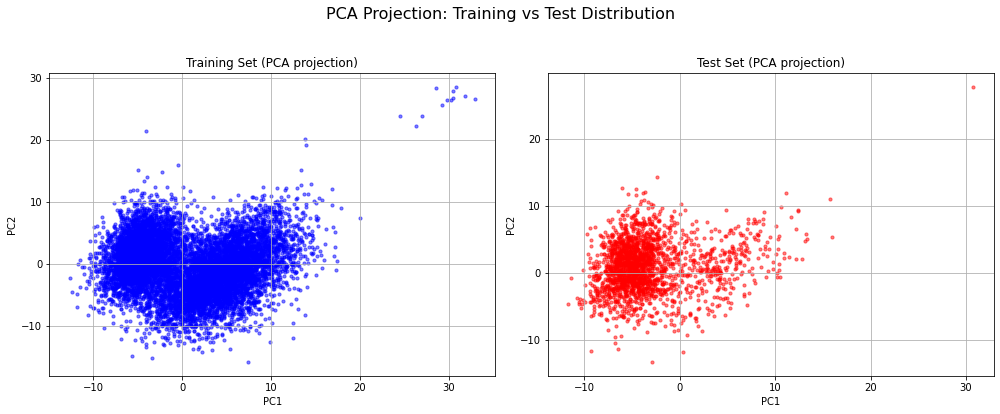

In [62]:
# Assume you now have these two:

# Set up the plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot train data
axes[0].scatter(X_train_pca[:, 0], X_train_pca[:, 1], alpha=0.5, s=10, color='blue')
axes[0].set_title('Training Set (PCA projection)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].grid(True)

# Plot test data
axes[1].scatter(X_new_pca[:, 0], X_new_pca[:, 1], alpha=0.5, s=10, color='red')
axes[1].set_title('Test Set (PCA projection)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].grid(True)

# Overall title
plt.suptitle('PCA Projection: Training vs Test Distribution', fontsize=16)

# Show
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()